In [25]:
# Bibliotecas para manipulação dos dados e cálculos
import time
import itertools
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

from shapely.ops import unary_union
from matplotlib.patches import Patch

import ast
import matplotlib.pyplot as plt
import pandas as pd

# Caminhos dos arquivos utilizados no problema
caminho_area = "PEmSE/area_interesse.shp"
caminho_passagens = "PEmSE/passagens_SAR.shp"

# Leitura dos shapefiles
AREAS_INTERESSE = gpd.read_file(caminho_area)
PASSAGENS_SAR = gpd.read_file(caminho_passagens)

# Verifica se os arquivos possuem sistema de coordenadas definido
if AREAS_INTERESSE.crs is None or PASSAGENS_SAR.crs is None:
    raise ValueError("Os shapefiles precisam ter CRS definido.")

# Reprojeta os dados para uma projeção equivalente, adequada para cálculos de área
AREAS_INTERESSE = AREAS_INTERESSE.to_crs("EPSG:6933")
PASSAGENS_SAR = PASSAGENS_SAR.to_crs("EPSG:6933")

# Remove geometrias nulas ou vazias
AREAS_INTERESSE = AREAS_INTERESSE[
    AREAS_INTERESSE.geometry.notna() & ~AREAS_INTERESSE.geometry.is_empty
].copy()

PASSAGENS_SAR = PASSAGENS_SAR[
    PASSAGENS_SAR.geometry.notna() & ~PASSAGENS_SAR.geometry.is_empty
].copy()

print("Área de interesse:", len(AREAS_INTERESSE), "geometria(s)")
print("Passagens SAR disponíveis:", len(PASSAGENS_SAR))

Área de interesse: 7 geometria(s)
Passagens SAR disponíveis: 702


# Projeta a área de interesse

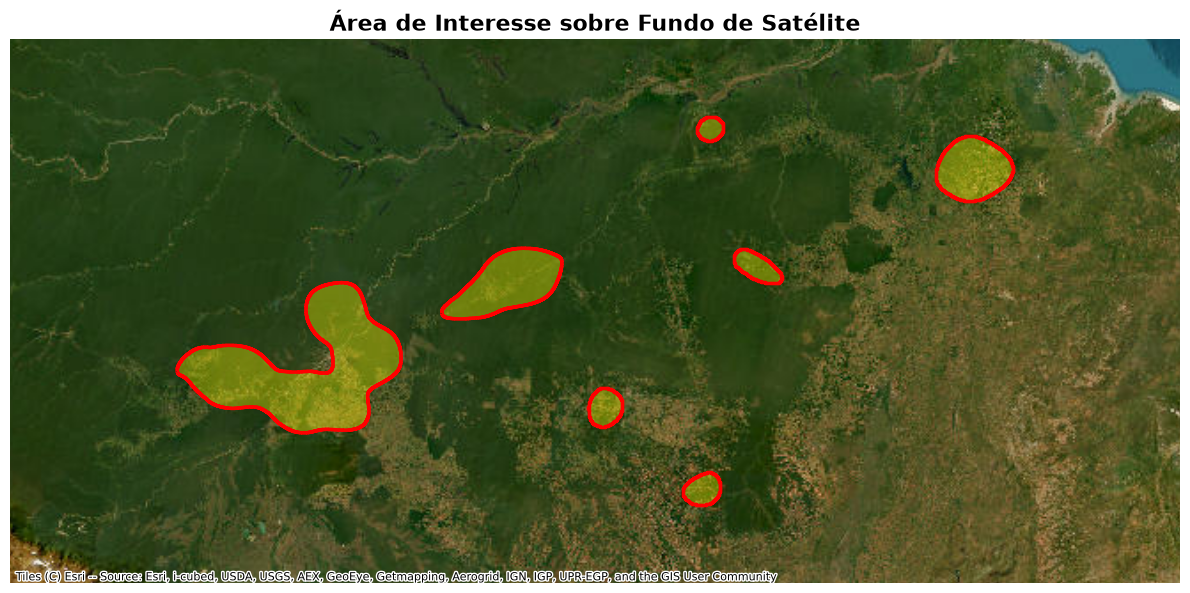

In [2]:
# Projeta a área de interesse

# Reprojetar a área para EPSG:3857, que permite usar o mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 10))

# Define o enquadramento com uma margem ao redor da área
xmin, ymin, xmax, ymax = area_plot.total_bounds
dx = xmax - xmin
dy = ymax - ymin
margem_x = dx * 0.20
margem_y = dy * 0.20
ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
try:
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, crs=area_plot.crs)
except Exception as erro:
    print("Mapa-base não foi carregado. A área será mostrada sem imagem de fundo.")

# Desenha a área de interesse
area_plot.plot(ax=ax, facecolor="yellow", edgecolor="red",
               alpha=0.35, linewidth=2.5, zorder=2)
area_plot.boundary.plot(ax=ax, color="red", linewidth=2.5, zorder=3)

ax.set_title("Área de Interesse sobre Fundo de Satélite", fontsize=16, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("area_interesse_amazonia_fundo.png", dpi=300, bbox_inches="tight")
plt.show()

# Definição do limite de passagens

In [3]:
# Definição do limite de passagens

# Limite máximo de passagens que uma solução poderá selecionar
LIMITE_DESEJADO = 70

# Une as geometrias da área de interesse
area_total_geom = unary_union(AREAS_INTERESSE.geometry.tolist())
area_total_km2 = area_total_geom.area / 1_000_000

if area_total_km2 <= 0:
    raise ValueError("A área de interesse possui área nula ou inválida.")

# Recorta cada passagem pela área de interesse uma única vez
geometrias_recortadas = []
areas_passagens_km2 = []

for geometria in PASSAGENS_SAR.geometry:
    if geometria is None or geometria.is_empty:
        recortada = None
    else:
        recortada = geometria.intersection(area_total_geom)
        if recortada.is_empty:
            recortada = None

    geometrias_recortadas.append(recortada)
    areas_passagens_km2.append(
        0.0 if recortada is None else recortada.area / 1_000_000
    )

areas_passagens_km2 = np.asarray(areas_passagens_km2, dtype=float)
N_PASSAGENS = len(PASSAGENS_SAR)
MAX_PASSAGENS = min(LIMITE_DESEJADO, N_PASSAGENS)

print(f"Área de interesse: {area_total_km2:.2f} km²")
print(f"Passagens disponíveis: {N_PASSAGENS}")
print(f"Limite por solução: {MAX_PASSAGENS} passagens")
print(f"Passagens que intersectam a área: {np.count_nonzero(areas_passagens_km2)}")

Área de interesse: 210259.77 km²
Passagens disponíveis: 702
Limite por solução: 70 passagens
Passagens que intersectam a área: 702


# Define a função objetivo

A função é a mesma utilizada na atividade do PSO.

- **AC(x):** proporção da área de interesse coberta pela união das passagens.
- **NP(x):** quantidade de passagens selecionadas dividida pelo limite permitido.
- **SO(x):** sobreposição espacial, calculada pela diferença entre a soma das áreas e a área da união, dividida pela soma das áreas.
- **w1, w2 e w3:** pesos dos critérios.

O objetivo é maximizar a cobertura e penalizar a quantidade de passagens e a sobreposição.

In [4]:
# Cache das métricas geométricas para evitar cálculos repetidos
cache_metricas_geometricas = {}

def calcular_metricas_geometricas(mascara):
    mascara = np.asarray(mascara, dtype=bool)
    chave = mascara.tobytes()

    if chave in cache_metricas_geometricas:
        return cache_metricas_geometricas[chave]

    indices = np.flatnonzero(mascara)
    quantidade = len(indices)

    if quantidade == 0:
        metricas = {"cobertura": 0.0, "np": 0.0,
                    "sobreposicao": 0.0, "quantidade": 0}
        cache_metricas_geometricas[chave] = metricas
        return metricas

    geometrias = [geometrias_recortadas[i] for i in indices
                  if geometrias_recortadas[i] is not None]
    soma_areas_km2 = areas_passagens_km2[indices].sum()

    if not geometrias or soma_areas_km2 <= 0:
        area_uniao_km2 = 0.0
    else:
        area_uniao_km2 = unary_union(geometrias).area / 1_000_000

    cobertura = min(area_uniao_km2 / area_total_km2, 1.0)
    np_ratio = quantidade / MAX_PASSAGENS

    if soma_areas_km2 > 0:
        sobreposicao = max(0.0, soma_areas_km2 - area_uniao_km2) / soma_areas_km2
    else:
        sobreposicao = 0.0

    metricas = {"cobertura": float(cobertura), "np": float(np_ratio),
                "sobreposicao": float(sobreposicao), "quantidade": int(quantidade)}
    cache_metricas_geometricas[chave] = metricas
    return metricas


def avaliar_solucao(mascara, pesos):
    metricas = calcular_metricas_geometricas(mascara)

    if metricas["quantidade"] == 0 or metricas["quantidade"] > MAX_PASSAGENS:
        return {"score": -1.0, **metricas}

    w1, w2, w3 = pesos
    score = (w1 * metricas["cobertura"]
             - w2 * metricas["np"]
             - w3 * metricas["sobreposicao"])

    return {"score": float(score), **metricas}

# Condição inicial

Neste notebook, o Simulated Annealing começa com uma solução aleatória esparsa. Não há construção gulosa no pré-processamento.

In [5]:
def inicial_aleatoria_esparsa(rng, taxa=0.08):
    # Começa selecionando poucas passagens aleatoriamente
    mascara = (rng.random(N_PASSAGENS) < taxa).astype(np.uint8)
    if mascara.sum() == 0:
        mascara[rng.integers(N_PASSAGENS)] = 1
    if mascara.sum() > MAX_PASSAGENS:
        ativos = np.flatnonzero(mascara)
        retirar = rng.choice(ativos, size=len(ativos)-MAX_PASSAGENS, replace=False)
        mascara[retirar] = 0
    return mascara

# Implementação do Simulated Annealing

In [17]:
def gerar_vizinho(mascara, tipo, rng):
    vizinho = mascara.copy()
    selecionadas = np.flatnonzero(vizinho)
    nao_selecionadas = np.flatnonzero(vizinho == 0)

    if tipo == "adicionar":
        if len(nao_selecionadas) and len(selecionadas) < MAX_PASSAGENS:
            vizinho[rng.choice(nao_selecionadas)] = 1

    elif tipo == "remover":
        if len(selecionadas) > 1:
            vizinho[rng.choice(selecionadas)] = 0

    elif tipo == "trocar":
        if len(selecionadas) and len(nao_selecionadas):
            tirar = rng.choice(selecionadas)
            colocar = rng.choice(nao_selecionadas)
            vizinho[tirar] = 0
            vizinho[colocar] = 1

    elif tipo == "mista":
        movimento = rng.choice(["adicionar", "remover", "trocar"])
        return gerar_vizinho(mascara, movimento, rng)
    else:
        raise ValueError("Tipo de vizinhança desconhecido.")

    # Garante que a solução não fique vazia nem ultrapasse o limite
    if vizinho.sum() == 0:
        vizinho[rng.integers(N_PASSAGENS)] = 1
    if vizinho.sum() > MAX_PASSAGENS:
        ativos = np.flatnonzero(vizinho)
        vizinho[rng.choice(ativos)] = 0
    return vizinho


def temperatura(k, total, T0, esquema, alpha=0.95):
    if esquema == "geometrico":
        return T0 * alpha ** k
    if esquema == "linear":
        return T0 * max(0.0, 1 - k / total)
    if esquema == "logaritmico":
        return T0 / np.log(k + 2)
    raise ValueError("Esquema de resfriamento desconhecido.")


def executar_sa(mascara_inicial, pesos, vizinhanca="mista",
                esquema="geometrico", T0=0.05, alpha=0.95,
                n_temperaturas=100, tentativas_por_temperatura=10,
                reaquecimento=False, seed=42):
    inicio = time.perf_counter()
    rng = np.random.default_rng(seed)

    atual = mascara_inicial.copy()
    score_atual = avaliar_solucao(atual, pesos)["score"]
    melhor = atual.copy()
    melhor_score = score_atual
    historico = [melhor_score]
    historico_T = [T0]
    sem_melhora = 0
    temperatura_atual = T0

    for k in range(n_temperaturas):
        temperatura_atual = temperatura(k, n_temperaturas, T0, esquema, alpha)

        # Reaquecimento: aumenta a temperatura após várias etapas sem melhora
        if reaquecimento and sem_melhora >= 15:
            temperatura_atual = max(temperatura_atual, T0 * 0.5)
            sem_melhora = 0

        for _ in range(tentativas_por_temperatura):
            candidato = gerar_vizinho(atual, vizinhanca, rng)
            score_candidato = avaliar_solucao(candidato, pesos)["score"]
            diferenca = score_candidato - score_atual

            # Aceita melhora sempre; aceita piora com uma probabilidade ligada à temperatura
            if diferenca >= 0:
                aceitar = True
            elif temperatura_atual > 0:
                aceitar = rng.random() < np.exp(diferenca / temperatura_atual)
            else:
                aceitar = False

            if aceitar:
                atual = candidato
                score_atual = score_candidato

            if score_candidato > melhor_score:
                melhor = candidato.copy()
                melhor_score = score_candidato
                sem_melhora = 0

        if melhor_score > historico[-1]:
            historico.append(float(melhor_score))
        else:
            historico.append(float(historico[-1]))
            sem_melhora += 1

        historico_T.append(temperatura_atual)

        metricas = avaliar_solucao(melhor, pesos)
        print(f"Interação {k+1}/{n_temperaturas} | Score: {melhor_score:.4f} | "
              f"Cobertura: {metricas['cobertura']*100:.2f}% | "
              f"Passagens: {metricas['quantidade']} | "
              f"Sobreposição: {metricas['sobreposicao']*100:.2f}%", flush=True)

    metricas_finais = avaliar_solucao(melhor, pesos)
    return {"mascara": melhor.copy(), "score": melhor_score,
            "historico": historico, "historico_temp": historico_T, **metricas_finais,
            "tempo_segundos": time.perf_counter() - inicio}

# Teste dos hiperparâmetros

Vamos variar as condições iniciais, vizinhanças, três formas de resfriamento e reaquecimento. Para reduzir o tempo inicial de execução, os parâmetros abaixo podem ser aumentados depois.

In [19]:
# Configurações para testar
condicoes_iniciais = ["Aleatória esparsa"]
vizinhancas = ["adicionar", "remover", "trocar", "mista"]
esquemas = ["geometrico", "linear", "logaritmico"]
reaquecimentos = [False, True]

# Parâmetros do SA (podem ser ajustados)
PESOS = (50.0, 0.05, 0.05)  # cobertura, quantidade, sobreposição
T0 = 0.05
ALPHA = 0.95
N_TEMPERATURAS = 300
TENTATIVAS_POR_T = 5
SEEDS = [42]  # pode incluir outras sementes para repetir os testes

combinacoes = list(itertools.product(
    condicoes_iniciais, vizinhancas, esquemas, reaquecimentos, SEEDS
))
print("Total de configurações:", len(combinacoes))

resultados = []
historicos_sa = {}
inicio_total = time.perf_counter()

for numero, (condicao, vizinhanca, esquema, reaquecimento, seed) in enumerate(combinacoes, start=1):
    print(f"\\nConfiguração {numero}/{len(combinacoes)}: {condicao}, {vizinhanca}, {esquema}, reaquecimento={reaquecimento}")
    rng = np.random.default_rng(seed)

    if condicao == "Aleatória esparsa":
        inicial = inicial_aleatoria_esparsa(rng)
    elif condicao == "Gulosa":
        inicial = inicial_gulosa(meta=0.99)
    elif condicao == "Gulosa perturbada":
        inicial = inicial_gulosa_perturbada(rng, meta=0.99)

    resultado = executar_sa(
        inicial, PESOS, vizinhanca=vizinhanca, esquema=esquema,
        T0=T0, alpha=ALPHA, n_temperaturas=N_TEMPERATURAS,
        tentativas_por_temperatura=TENTATIVAS_POR_T,
        reaquecimento=reaquecimento, seed=seed
    )

    chave = (condicao, vizinhanca, esquema, reaquecimento, seed)
    historicos_sa[chave] = resultado["historico"]

    resultados.append({
        "condicao_inicial": condicao,
        "vizinhanca": vizinhanca,
        "resfriamento": esquema,
        "reaquecimento": reaquecimento,
        "seed": seed,
        "score": resultado["score"],
        "cobertura_pct": resultado["cobertura"] * 100,
        "passagens": resultado["quantidade"],
        "sobreposicao_pct": resultado["sobreposicao"] * 100,
        "tempo_segundos": resultado["tempo_segundos"],
        "mascara": resultado["mascara"],
        "historico": resultado["historico"],
        "historico_temp": resultado["historico_temp"]
    })

df_sa = pd.DataFrame(resultados)
print(f"Tempo total: {(time.perf_counter()-inicio_total)/60:.2f} min")

Total de configurações: 24
\nConfiguração 1/24: Aleatória esparsa, adicionar, geometrico, reaquecimento=False
Interação 1/300 | Score: 31.2282 | Cobertura: 62.57% | Passagens: 52 | Sobreposição: 36.75%
Interação 2/300 | Score: 31.7947 | Cobertura: 63.71% | Passagens: 57 | Sobreposição: 42.38%
Interação 3/300 | Score: 33.2702 | Cobertura: 66.67% | Passagens: 61 | Sobreposição: 43.44%
Interação 4/300 | Score: 33.4882 | Cobertura: 67.12% | Passagens: 67 | Sobreposição: 45.88%
Interação 5/300 | Score: 34.2223 | Cobertura: 68.59% | Passagens: 70 | Sobreposição: 46.41%
Interação 6/300 | Score: 34.2223 | Cobertura: 68.59% | Passagens: 70 | Sobreposição: 46.41%
Interação 7/300 | Score: 34.2223 | Cobertura: 68.59% | Passagens: 70 | Sobreposição: 46.41%
Interação 8/300 | Score: 34.2223 | Cobertura: 68.59% | Passagens: 70 | Sobreposição: 46.41%
Interação 9/300 | Score: 34.2223 | Cobertura: 68.59% | Passagens: 70 | Sobreposição: 46.41%
Interação 10/300 | Score: 34.2223 | Cobertura: 68.59% | Passag

# Comparação das configurações

A tabela é ordenada pelo score, que é maximizado. Também mostramos as soluções que atingiram pelo menos 99% de cobertura.

In [20]:
colunas_exibicao = [
    "condicao_inicial", "vizinhanca", "resfriamento", "reaquecimento",
    "score", "cobertura_pct", "passagens", "sobreposicao_pct", "tempo_segundos"
]

df_sa_ordenado = df_sa.sort_values("score", ascending=False).reset_index(drop=True)
display(df_sa_ordenado[colunas_exibicao].head(10))

# Resultados que atingiram a meta de cobertura de 99%
df_99 = df_sa_ordenado[df_sa_ordenado["cobertura_pct"] >= 99]
display(df_99[colunas_exibicao].head(10))

# Salva a tabela para usar no artigo ou nos slides
df_sa_ordenado[colunas_exibicao].to_csv("resultados_simulated_annealing.csv", index=False)
print("Tabela salva.")

,condicao_inicial,vizinhanca,resfriamento,reaquecimento,score,cobertura_pct,passagens,sobreposicao_pct,tempo_segundos
0,Aleatória esparsa,mista,linear,True,49.223910,98.582485,70,34.666132,0.431807
1,Aleatória esparsa,mista,linear,False,49.223910,98.582485,70,34.666132,0.430311
2,Aleatória esparsa,mista,logaritmico,True,48.775111,97.681648,68,34.283126,0.444523
3,Aleatória esparsa,mista,logaritmico,False,48.775111,97.681648,68,34.283126,0.474888
4,Aleatória esparsa,mista,geometrico,False,48.610888,97.355728,69,35.381010,0.425205
5,Aleatória esparsa,mista,geometrico,True,48.610888,97.355728,69,35.381010,0.438222
6,Aleatória esparsa,trocar,logaritmico,False,45.837147,91.761047,47,19.609652,0.399706
7,Aleatória esparsa,trocar,logaritmico,True,45.837147,91.761047,47,19.609652,0.384956
8,Aleatória esparsa,trocar,linear,True,45.691325,91.468512,47,18.718206,0.393154
9,Aleatória esparsa,trocar,linear,False,45.691325,91.468512,47,18.718206,0.381439


,condicao_inicial,vizinhanca,resfriamento,reaquecimento,score,cobertura_pct,passagens,sobreposicao_pct,tempo_segundos


Tabela salva.


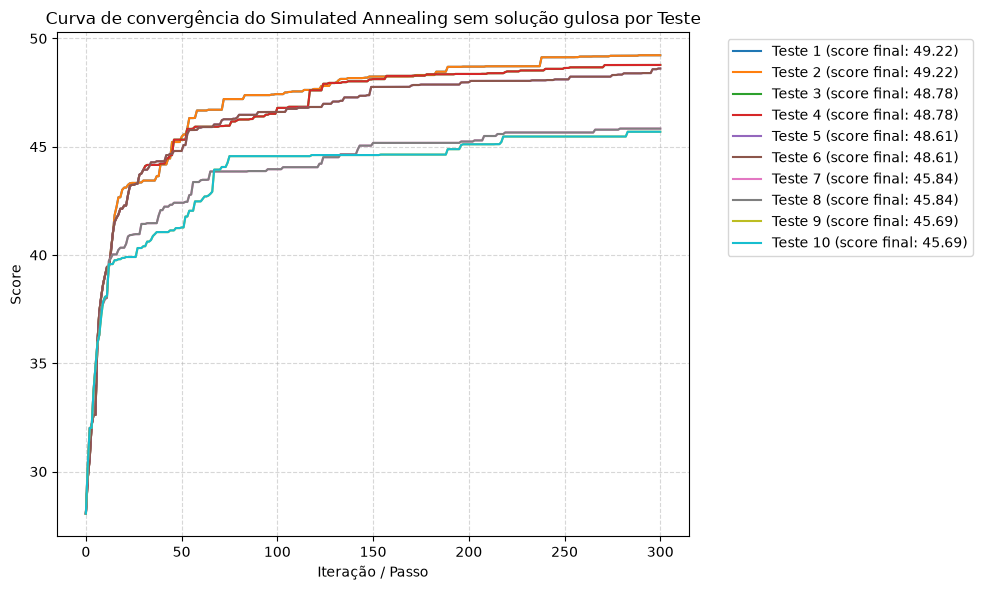

In [42]:
plt.figure(figsize=(10, 6))

df_sa_ = df_sa_ordenado.copy().head(10)

for idx, row in df_sa_.iterrows():
    hist = row["historico"]
    
    # Caso a coluna 'historico' esteja salva como string, converte para lista
    if isinstance(hist, str):
        hist = ast.literal_eval(hist)

    plt.plot(hist, label=f"Teste {idx+1} (score final: {row['score']:.2f})")

plt.title("Curva de convergência do Simulated Annealing sem solução gulosa por Teste")
plt.xlabel("Iteração / Passo")
plt.ylabel("Score")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

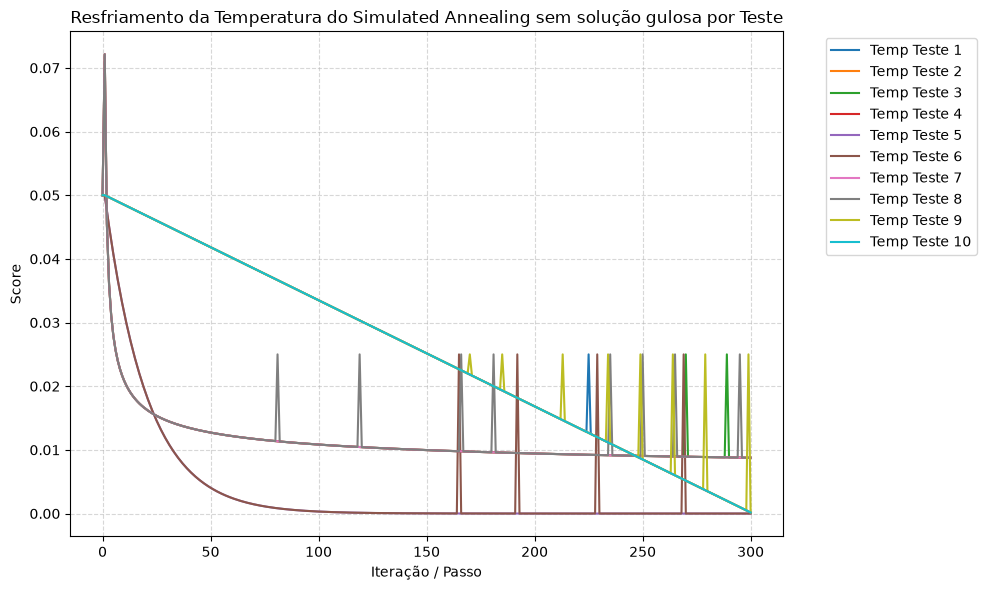

In [43]:
plt.figure(figsize=(10, 6))

df_sa_ = df_sa_ordenado.copy().head(10)

for idx, row in df_sa_.iterrows():
    hist_t = row["historico_temp"]

    # Caso a coluna 'historico_temp' esteja salva como string, converte para lista
    if isinstance(hist_t, str):
        hist_t = ast.literal_eval(hist_t)
        
    plt.plot(hist_t, label=f"Temp Teste {idx+1}")

plt.title("Resfriamento da Temperatura do Simulated Annealing sem solução gulosa por Teste")
plt.xlabel("Iteração / Passo")
plt.ylabel("Score")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Curva de convergência

Mostra a evolução da melhor solução encontrada durante a execução da configuração vencedora.

condicao_inicial                                    Aleatória esparsa
vizinhanca                                                      mista
resfriamento                                                   linear
reaquecimento                                                    True
seed                                                               42
score                                                        49.22391
cobertura_pct                                               98.582485
passagens                                                          70
sobreposicao_pct                                            34.666132
tempo_segundos                                               0.431807
mascara             [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...
historico           [28.058903476912963, 29.706222291411333, 30.60...
historico_temp      [0.05, 0.05, 0.04983333333333334, 0.0496666666...
Name: 0, dtype: object


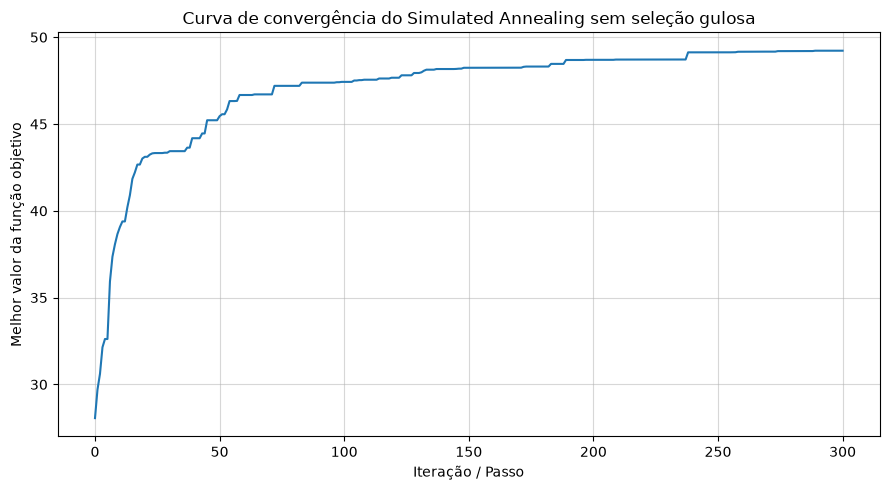

In [44]:
melhor_resultado = df_sa_ordenado.iloc[0]
chave_melhor = (
    melhor_resultado["condicao_inicial"], melhor_resultado["vizinhanca"],
    melhor_resultado["resfriamento"], melhor_resultado["reaquecimento"],
    int(melhor_resultado["seed"])
)
historico_melhor = historicos_sa[chave_melhor]

print(melhor_resultado)

plt.figure(figsize=(9, 5))
plt.plot(range(len(historico_melhor)), historico_melhor)
plt.xlabel("Iteração / Passo")
plt.ylabel("Melhor valor da função objetivo")
plt.title("Curva de convergência do Simulated Annealing sem seleção gulosa")
# plt.xticks(range(0, len(historico_melhor), max(1, len(historico_melhor)//10)))
plt.grid(True, linestyle="-", alpha=0.5)
plt.tight_layout()
plt.show()

# Visualização da melhor configuração

# Recupera a máscara da melhor solução
melhor_mascara_sa = np.asarray(melhor_resultado["mascara"], dtype=bool)
passagens_escolhidas_sa = PASSAGENS_SAR.loc[melhor_mascara_sa].copy()

# Reprojeta os dados para o sistema do mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
passagens_plot = passagens_escolhidas_sa.to_crs(epsg=3857)
passagens_recortadas_plot = gpd.clip(passagens_plot, area_plot)

fig, ax = plt.subplots(figsize=(12, 10))
xmin, ymin, xmax, ymax = area_plot.total_bounds
dx, dy = xmax - xmin, ymax - ymin
ax.set_xlim(xmin - dx*0.20, xmax + dx*0.20)
ax.set_ylim(ymin - dy*0.20, ymax + dy*0.20)

# Fundo de satélite
try:
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, crs=area_plot.crs)
except Exception:
    print("Mapa-base indisponível; exibindo sem imagem de satélite.")

# Área de interesse
area_plot.plot(ax=ax, facecolor="yellow", edgecolor="red",
               alpha=0.35, linewidth=2.5, zorder=2)
area_plot.boundary.plot(ax=ax, color="red", linewidth=2.5, zorder=3)

# Passagens selecionadas
if not passagens_recortadas_plot.empty:
    passagens_recortadas_plot.plot(ax=ax, facecolor="cyan", edgecolor="black",
                                   hatch="||||", alpha=0.85, linewidth=0.5, zorder=4)

legenda = [
    Patch(facecolor="yellow", edgecolor="red", alpha=0.35, label="Área de Interesse"),
    Patch(facecolor="cyan", edgecolor="black", hatch="||||", label="Passagens SAR selecionadas")
]
ax.legend(handles=legenda, loc="upper right", fontsize=9)
ax.set_title("Passagens SAR Selecionadas na Área de Interesse", fontsize=15, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("resultado_final_SA.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Score: {melhor_resultado['score']:.4f}")
print(f"Cobertura: {melhor_resultado['cobertura_pct']:.2f}%")
print(f"Passagens: {melhor_resultado['passagens']}")
print(f"Sobreposição: {melhor_resultado['sobreposicao_pct']:.2f}%")

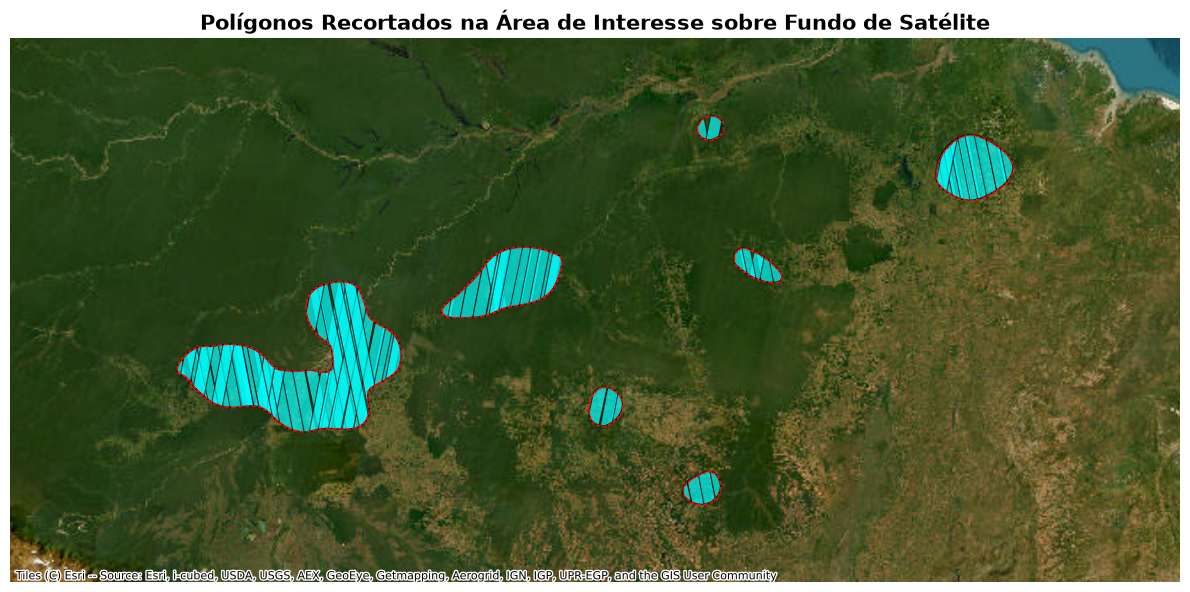

Score: 49.2239
Cobertura: 98.58%
Passagens: 70
Sobreposição: 34.67%


In [40]:
# Visualização da melhor configuração
melhor_mascara_sa = np.asarray(melhor_resultado["mascara"], dtype=bool)
passagens_escolhidas = PASSAGENS_SAR.iloc[melhor_mascara_sa.astype(bool)]

# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = passagens_escolhidas.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Score: {melhor_resultado['score']:.4f}")
print(f"Cobertura: {melhor_resultado['cobertura_pct']:.2f}%")
print(f"Passagens: {melhor_resultado['passagens']}")
print(f"Sobreposição: {melhor_resultado['sobreposicao_pct']:.2f}%")

# Salvar resultados

In [41]:
# Salva a seleção final
passagens_escolhidas_sa.to_file("passagens_selecionadas_SA.shp")
np.save("mascara_melhor_SA.npy", melhor_mascara_sa)
print("Arquivos salvos: shapefile e máscara numpy.")

Arquivos salvos: shapefile e máscara numpy.


# Observações

- O SA trabalha com uma solução por vez.
- A vizinhança define como a solução é modificada.
- A temperatura controla a chance de aceitar uma solução pior.
- O reaquecimento tenta recuperar a exploração quando o algoritmo fica muitas etapas sem melhorar.
- Para avaliar melhor, repita com mais sementes e compare a cobertura, número de passagens, sobreposição e score.